In [ ]:
# Hansı kampaniya ən yüksək qəbul faizinə sahibdir?

# Kampaniyalara ümumilikdə neçə müştəri müsbət reaksiya verib?

# Müştərilərin yaş və gəlir səviyyəsi kampaniya reaksiyası ilə necə əlaqəlidir?

# Hansı müştəri seqmentləri kampaniyalara daha çox müsbət reaksiya verir?

# Daha yüksək xərcləmə edən müştərilər kampaniyalara daha çox reaksiya verirlərmi?

# Gələcək kampaniyalar üçün hansı seqmentləri test etməliyik?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

file_path = Path(
    "../05_Clean_Data/marketing_data_clean.csv"
)

df = pd.read_csv(file_path)

print("Dataset Shape:", df.shape)

display(df.head())

Dataset Shape: (2240, 40)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Response,Complain,Country,Total_Purchases,Deal_Purchase_Issue,Total_Spending,Zero_Purchase_Spending_Issue,Has_Data_Quality_Issue,Data_Quality_Status,Income_Imputed,Education_Standardized,Marital_Status_Group,Customer_Age_Estimated,Age_Group,Income_Group
0,1826,1970,Graduation,Divorced,84835.0,0,0,2014-06-16,0,189,104,379,111,189,218,1,4,4,6,1,0,0,0,0,0,1,0,Spain,14,0,1190,0,0,No Flagged Issue,84835.0,Graduate,Divorced,44,35-44,High Income
1,1,1961,Graduation,Single,57091.0,0,0,2014-06-15,0,464,5,64,7,0,37,1,7,3,7,5,0,0,0,0,1,1,0,Canada,17,0,577,0,0,No Flagged Issue,57091.0,Graduate,Single,53,45-54,Upper-Middle Income
2,10476,1958,Graduation,Married,67267.0,0,1,2014-05-13,0,134,11,59,15,2,30,1,3,2,5,2,0,0,0,0,0,0,0,USA,10,0,251,0,0,No Flagged Issue,67267.0,Graduate,Married,56,55-64,Upper-Middle Income
3,1386,1967,Graduation,Together,32474.0,1,1,2014-05-11,0,10,0,1,0,0,0,1,1,0,2,7,0,0,0,0,0,0,0,Australia,3,0,11,0,0,No Flagged Issue,32474.0,Graduate,Partnered,47,45-54,Low Income
4,5371,1989,Graduation,Single,21474.0,1,0,2014-04-08,0,6,16,24,11,0,34,2,3,1,2,7,1,0,0,0,0,1,0,Spain,6,0,91,0,0,No Flagged Issue,21474.0,Graduate,Single,25,25-34,Low Income


In [2]:
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

campaign_names = {
    "AcceptedCmp1": "Campaign 1",
    "AcceptedCmp2": "Campaign 2",
    "AcceptedCmp3": "Campaign 3",
    "AcceptedCmp4": "Campaign 4",
    "AcceptedCmp5": "Campaign 5",
    "Response": "Last Campaign"
}

display(
    df[campaign_columns].describe().T
)

,count,mean,std,min,25%,50%,75%,max
AcceptedCmp1,2240.0,0.064286,0.245316,0.0,0.0,0.0,0.0,1.0
AcceptedCmp2,2240.0,0.013393,0.114976,0.0,0.0,0.0,0.0,1.0
AcceptedCmp3,2240.0,0.072768,0.259813,0.0,0.0,0.0,0.0,1.0
AcceptedCmp4,2240.0,0.074554,0.262728,0.0,0.0,0.0,0.0,1.0
AcceptedCmp5,2240.0,0.072768,0.259813,0.0,0.0,0.0,0.0,1.0
Response,2240.0,0.149107,0.356274,0.0,0.0,0.0,0.0,1.0


In [3]:
for col in campaign_columns:

    print(
        col,
        df[col].value_counts(dropna=False).to_dict()
    )

AcceptedCmp1 {0: 2096, 1: 144}
AcceptedCmp2 {0: 2210, 1: 30}
AcceptedCmp3 {0: 2077, 1: 163}
AcceptedCmp4 {0: 2073, 1: 167}
AcceptedCmp5 {0: 2077, 1: 163}
Response {0: 1906, 1: 334}


In [4]:
campaign_performance = pd.DataFrame({
    "Campaign": campaign_columns,
    "Accepted_Customers": [
        (df[col] == 1).sum()
        for col in campaign_columns
    ],
    "Evaluated_Customers": [
        df[col].notna().sum()
        for col in campaign_columns
    ]
})

campaign_performance["Acceptance_Rate"] = (
    campaign_performance["Accepted_Customers"]
    / campaign_performance["Evaluated_Customers"]
    * 100
).round(2)

campaign_performance["Campaign"] = (
    campaign_performance["Campaign"]
    .replace(campaign_names)
)

display(campaign_performance)

,Campaign,Accepted_Customers,Evaluated_Customers,Acceptance_Rate
0,Campaign 1,144,2240,6.43
1,Campaign 2,30,2240,1.34
2,Campaign 3,163,2240,7.28
3,Campaign 4,167,2240,7.46
4,Campaign 5,163,2240,7.28
5,Last Campaign,334,2240,14.91


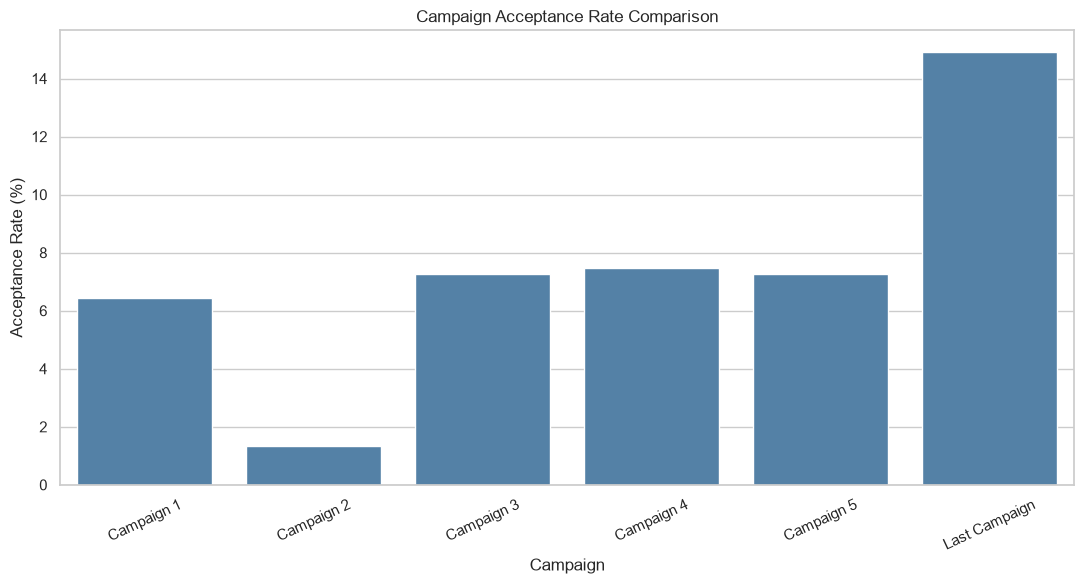

In [5]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=campaign_performance,
    x="Campaign",
    y="Acceptance_Rate",
    color="steelblue"
)

plt.title("Campaign Acceptance Rate Comparison")
plt.xlabel("Campaign")
plt.ylabel("Acceptance Rate (%)")

plt.xticks(rotation=25)

plt.tight_layout()
plt.show()

In [10]:
total_acceptances = (
    campaign_performance["Accepted_Customers"].sum()
)

campaign_performance["Acceptance_Share"] = (
    campaign_performance["Accepted_Customers"]
    / total_acceptances
    * 100
).round(2)

display(campaign_performance)

,Campaign,Accepted_Customers,Evaluated_Customers,Acceptance_Rate,Acceptance_Share
0,Campaign 1,144,2240,6.43,14.39
1,Campaign 2,30,2240,1.34,3.00
2,Campaign 3,163,2240,7.28,16.28
3,Campaign 4,167,2240,7.46,16.68
4,Campaign 5,163,2240,7.28,16.28
5,Last Campaign,334,2240,14.91,33.37


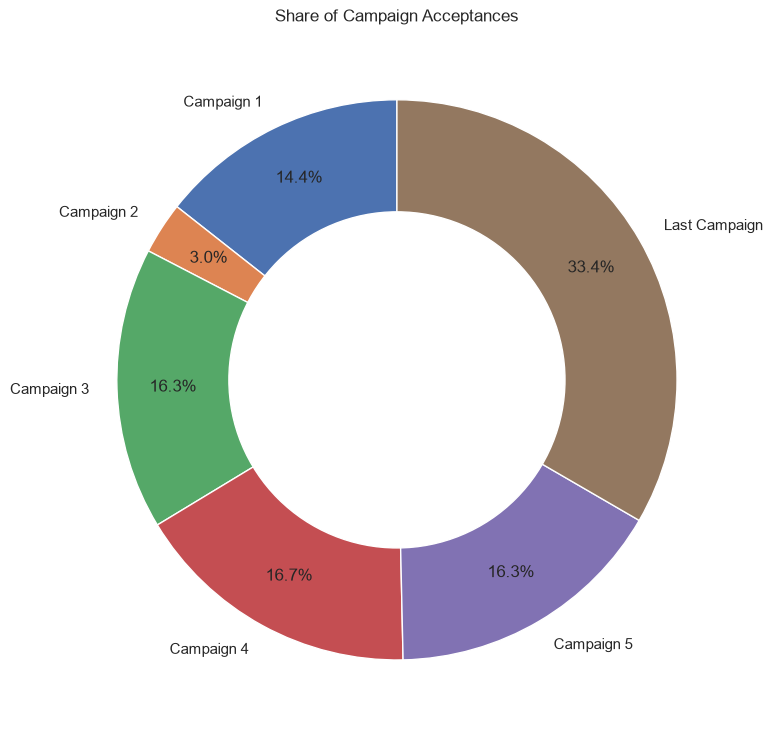

In [7]:
plt.figure(figsize=(8, 8))

plt.pie(
    campaign_performance["Accepted_Customers"],
    labels=campaign_performance["Campaign"],
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.8
)

centre_circle = plt.Circle(
    (0, 0),
    0.60,
    fc="white"
)

plt.gca().add_artist(centre_circle)

plt.title("Share of Campaign Acceptances")

plt.tight_layout()
plt.show()

In [12]:
campaign_columns = [
    "AcceptedCmp1",
    "AcceptedCmp2",
    "AcceptedCmp3",
    "AcceptedCmp4",
    "AcceptedCmp5",
    "Response"
]

df["Total_Accepted_Campaigns"] = (
    df[campaign_columns].sum(axis=1)
)

display(
    df[
        [
            "ID",
            "Total_Accepted_Campaigns"
        ]
    ].head(10)
)

print(
    "Total Campaign Acceptances:",
    df["Total_Accepted_Campaigns"].sum()
)

display(
    df["Total_Accepted_Campaigns"]
    .value_counts()
    .sort_index()
)

,ID,Total_Accepted_Campaigns
0,1826,1
1,1,2
2,10476,0
3,1386,0
4,5371,2
5,7348,1
6,4073,2
7,1991,0
8,4047,0
9,9477,0


Total Campaign Acceptances: 1001


Total_Accepted_Campaigns
0    1631
1     370
2     142
3      51
4      36
5      10
Name: count, dtype: int64

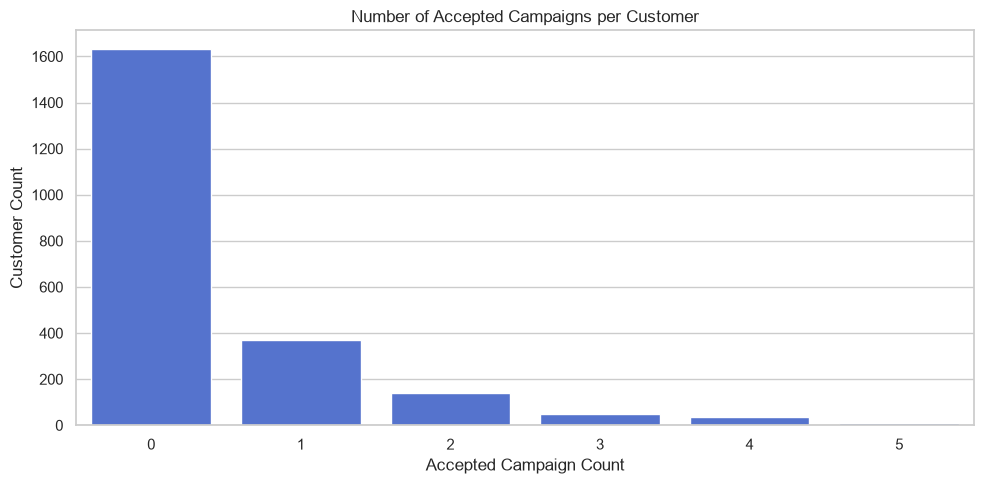

In [13]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="Total_Accepted_Campaigns",
    color="royalblue"
)

plt.title("Number of Accepted Campaigns per Customer")
plt.xlabel("Accepted Campaign Count")
plt.ylabel("Customer Count")

plt.tight_layout()
plt.show()

In [14]:
df["Campaign_Engagement_Segment"] = np.select(
    [
        df["Total_Accepted_Campaigns"] == 0,
        df["Total_Accepted_Campaigns"] == 1,
        df["Total_Accepted_Campaigns"] >= 2
    ],
    [
        "Never Responded",
        "Single Responder",
        "Multi Responder"
    ],
    default="Unknown"
)

In [15]:
engagement_analysis = (
    df.groupby("Campaign_Engagement_Segment")
    .agg(
        Total_Customers=("ID", "nunique"),
        Avg_Spending=("Total_Spending", "mean"),
        Avg_Purchases=("Total_Purchases", "mean")
    )
    .reset_index()
)

display(engagement_analysis.round(2))

,Campaign_Engagement_Segment,Total_Customers,Avg_Spending,Avg_Purchases
0,Multi Responder,239,1266.43,17.46
1,Never Responded,1631,458.11,11.32
2,Single Responder,370,830.10,14.73


In [16]:
age_response = (
    df.groupby("Age_Group", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Accepted_Customers=("Response", "sum"),
        Response_Rate=("Response", "mean")
    )
    .reset_index()
)

age_response["Response_Rate"] = (
    age_response["Response_Rate"] * 100
).round(2)

display(age_response)

,Age_Group,Total_Customers,Accepted_Customers,Response_Rate
0,18-24,61,14,22.95
1,25-34,363,67,18.46
2,35-44,740,105,14.19
3,45-54,506,63,12.45
4,55-64,460,59,12.83
5,65+,107,26,24.30
6,NaN,3,0,0.00


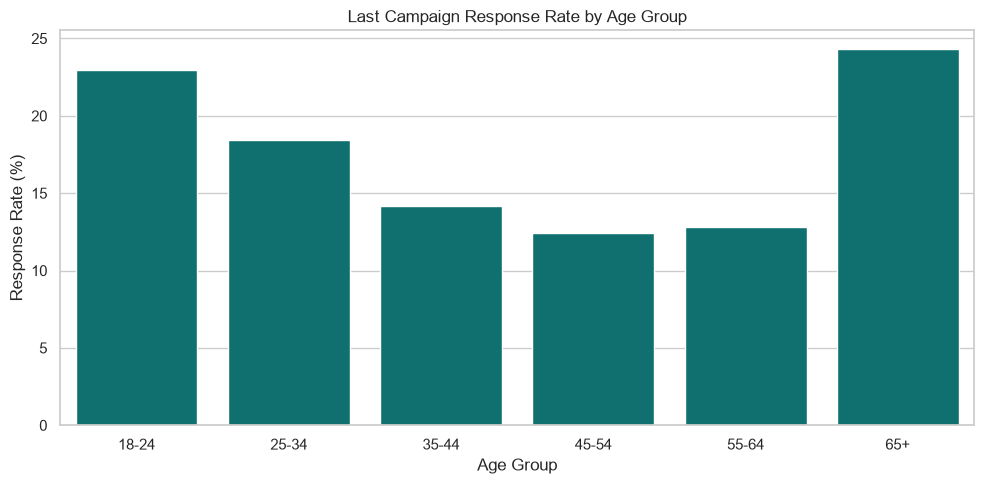

In [17]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=age_response,
    x="Age_Group",
    y="Response_Rate",
    color="teal"
)

plt.title("Last Campaign Response Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Response Rate (%)")

plt.tight_layout()
plt.show()

In [18]:
income_response = (
    df.groupby("Income_Group", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Accepted_Customers=("Response", "sum"),
        Response_Rate=("Response", "mean"),
        Avg_Spending=("Total_Spending", "mean")
    )
    .reset_index()
)

income_response["Response_Rate"] = (
    income_response["Response_Rate"] * 100
).round(2)

display(income_response)

,Income_Group,Total_Customers,Accepted_Customers,Response_Rate,Avg_Spending
0,High Income,554,149,26.90,1357.651625
1,Low Income,554,58,10.47,81.592058
2,Lower-Middle Income,554,69,12.45,231.315884
3,Upper-Middle Income,554,57,10.29,757.741877
4,NaN,24,1,4.17,487.875000


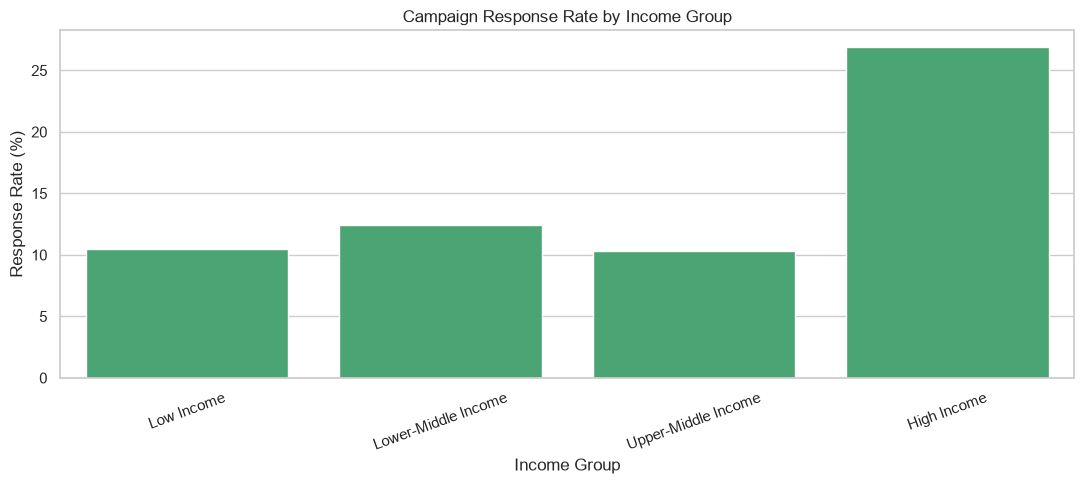

In [19]:
income_order = [
    "Low Income",
    "Lower-Middle Income",
    "Upper-Middle Income",
    "High Income"
]

plt.figure(figsize=(11, 5))

sns.barplot(
    data=income_response,
    x="Income_Group",
    y="Response_Rate",
    order=income_order,
    color="mediumseagreen"
)

plt.title("Campaign Response Rate by Income Group")
plt.xlabel("Income Group")
plt.ylabel("Response Rate (%)")

plt.xticks(rotation=20)

plt.tight_layout()
plt.show()

In [20]:
education_response = (
    df.groupby("Education_Standardized", dropna=False)
    .agg(
        Total_Customers=("ID", "nunique"),
        Accepted_Customers=("Response", "sum"),
        Response_Rate=("Response", "mean")
    )
    .reset_index()
)

education_response["Response_Rate"] = (
    education_response["Response_Rate"] * 100
).round(2)

display(
    education_response.sort_values(
        "Response_Rate",
        ascending=False
    )
)

,Education_Standardized,Total_Customers,Accepted_Customers,Response_Rate
1,Doctorate,486,101,20.78
3,Master's Degree,370,57,15.41
2,Graduate,1127,152,13.49
4,Second Cycle,203,22,10.84
0,Basic Education,54,2,3.70


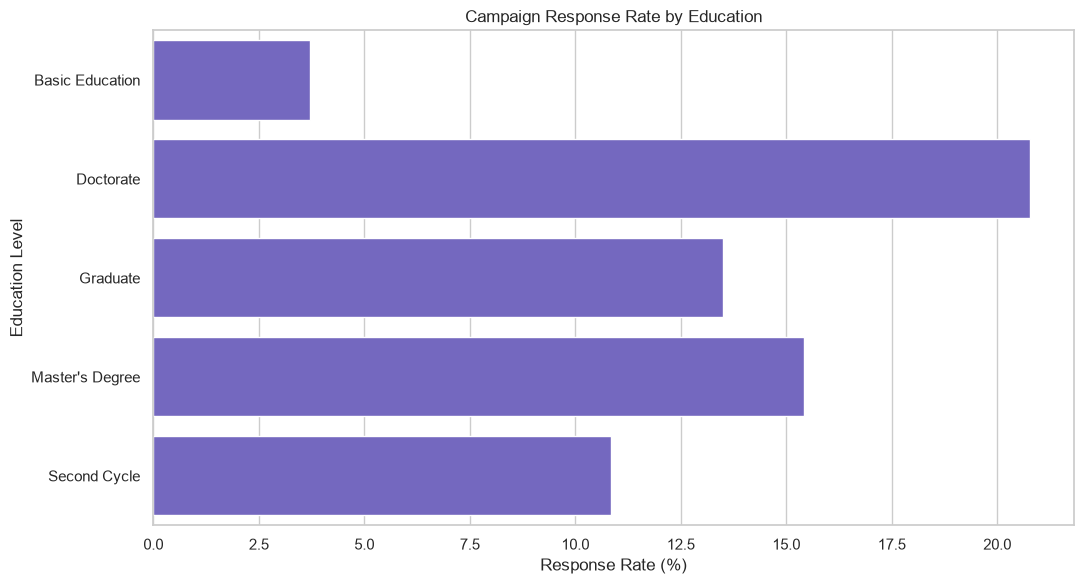

In [21]:
plt.figure(figsize=(11, 6))

sns.barplot(
    data=education_response,
    y="Education_Standardized",
    x="Response_Rate",
    color="slateblue"
)

plt.title("Campaign Response Rate by Education")
plt.xlabel("Response Rate (%)")
plt.ylabel("Education Level")

plt.tight_layout()
plt.show()

In [22]:
spending_threshold = (
    df["Total_Spending"].quantile(0.75)
)

df["Customer_Value_Segment"] = np.where(
    df["Total_Spending"] > spending_threshold,
    "High Value",
    "Regular"
)

In [23]:
value_response = (
    df.groupby("Customer_Value_Segment")
    .agg(
        Total_Customers=("ID", "nunique"),
        Accepted_Customers=("Response", "sum"),
        Response_Rate=("Response", "mean"),
        Avg_Spending=("Total_Spending", "mean")
    )
    .reset_index()
)

value_response["Response_Rate"] = (
    value_response["Response_Rate"] * 100
).round(2)

display(value_response)

,Customer_Value_Segment,Total_Customers,Accepted_Customers,Response_Rate,Avg_Spending
0,High Value,560,168,30.00,1490.475000
1,Regular,1680,166,9.88,310.905952


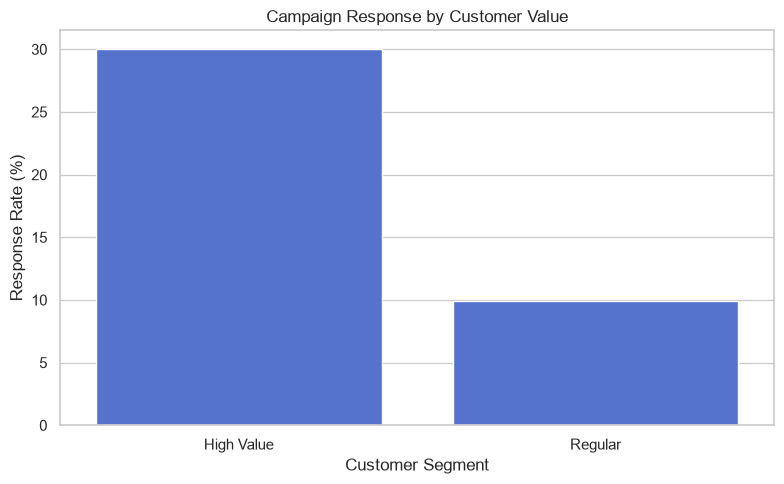

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=value_response,
    x="Customer_Value_Segment",
    y="Response_Rate",
    color="royalblue"
)

plt.title("Campaign Response by Customer Value")
plt.xlabel("Customer Segment")
plt.ylabel("Response Rate (%)")

plt.tight_layout()
plt.show()

In [25]:
campaign_long = df.melt(
    id_vars=["ID", "Age_Group"],
    value_vars=campaign_columns,
    var_name="Campaign",
    value_name="Accepted"
)

campaign_long["Campaign"] = (
    campaign_long["Campaign"]
    .replace(campaign_names)
)

In [26]:
campaign_heatmap = (
    campaign_long.groupby(
        ["Age_Group", "Campaign"],
        observed=True
    )["Accepted"]
    .mean()
    .unstack()
    * 100
)

display(campaign_heatmap.round(2))

Campaign,Campaign 1,Campaign 2,Campaign 3,Campaign 4,Campaign 5,Last Campaign
Age_Group,,,,,,
18-24,11.48,3.28,11.48,6.56,18.03,22.95
25-34,7.71,0.83,10.47,5.23,10.47,18.46
35-44,5.00,1.08,7.84,5.95,5.14,14.19
45-54,5.14,1.58,5.14,9.09,5.34,12.45
55-64,6.96,1.96,5.65,8.48,6.74,12.83
65+,13.08,0.00,7.48,14.02,15.89,24.30


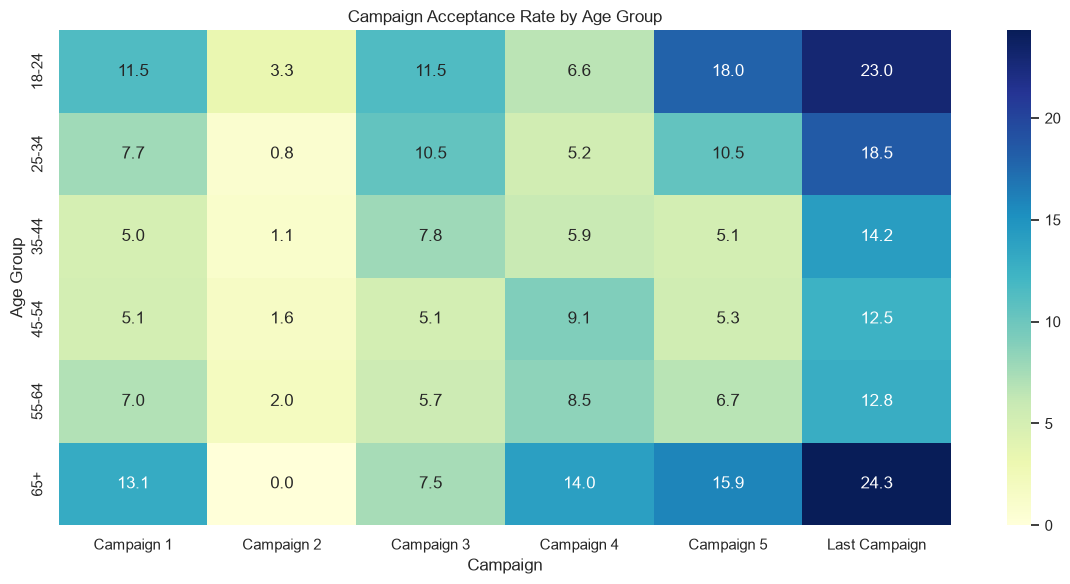

In [27]:
plt.figure(figsize=(12, 6))

sns.heatmap(
    campaign_heatmap,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu"
)

plt.title("Campaign Acceptance Rate by Age Group")
plt.xlabel("Campaign")
plt.ylabel("Age Group")

plt.tight_layout()
plt.show()

In [28]:
calculated_acceptances = (
    df[campaign_columns].sum(axis=1)
)

difference = (
    df["Total_Accepted_Campaigns"]
    - calculated_acceptances
)

print(
    "Campaign Count Differences:",
    (difference != 0).sum()
)

Campaign Count Differences: 0


In [29]:
print(
    "Total Accepted Campaign Events:",
    df[campaign_columns].sum().sum()
)

print(
    "Derived Accepted Campaign Events:",
    df["Total_Accepted_Campaigns"].sum()
)

Total Accepted Campaign Events: 1001
Derived Accepted Campaign Events: 1001


In [30]:
campaign_performance_summary = (
    campaign_performance[
        [
            "Campaign",
            "Accepted_Customers",
            "Evaluated_Customers",
            "Acceptance_Rate",
            "Acceptance_Share"
        ]
    ]
    .sort_values(
        "Acceptance_Rate",
        ascending=False
    )
)

display(campaign_performance_summary)

,Campaign,Accepted_Customers,Evaluated_Customers,Acceptance_Rate,Acceptance_Share
5,Last Campaign,334,2240,14.91,33.37
3,Campaign 4,167,2240,7.46,16.68
2,Campaign 3,163,2240,7.28,16.28
4,Campaign 5,163,2240,7.28,16.28
0,Campaign 1,144,2240,6.43,14.39
1,Campaign 2,30,2240,1.34,3.00
